การเรียนรู้ของเครื่องสำหรับอุตสาหกรรม -- ดร.วโรดม ตู้จินดา

# 1 บทนำ

ในงานอุตสาหกรรมทั่วไป วิศวกรสามารถออกแบบ/ใช้งานตัวควบคุมเช่น PID (Proportional Integral Derivative) หรือ LQR (Linear Quadratic Regulator) ให้เครื่องจักรกลทำงานได้ตามวัตถุประสงค์ มีค่าเผื่อเสถียรภาพรวมถึงข้อกำหนดสมรรถนะตามที่กำหนด ในกรณีที่มีการรบกวนเขาสามารถใช้วิธีการเช่นตัวกรองคาลมานเข้าช่วย วิธีการเหล่านี้มีพื้นฐานอยู่บนโมเดลทางคณิตศาสตร์ของเครื่องจักร ที่อาจหาจากหลักการทางฟิสิกส์หรือวิธีการหาเอกลักษณ์ระบบ (system identification) แม้ไม่ถูกต้องสมบูรณ์ 100% แต่เป็นตัวแทนที่ดีของเครื่องจักรจริงได้ในระดับหนึ่ง

เนื้อหาของหนังสือเล่มนี้จะเกี่ยวข้องกับปัญหาที่แตกต่างออกไป คือในกรณีที่เราทราบฟิสิกส์เพียงบางส่วน หรือมีค่าใช้จ่ายสูงเกินไปในการหาโมเดล หรือต้องการทำนายผลจากสัญญาณที่ไม่สามารถอ่านได้โดยสายตาสำหรับงานอุตสาหกรรมประเภทต่างๆ ตัวอย่างเช่นในการบำรุงรักษาเชิงป้องกัน (preventive maintenance) ต้องการทราบว่าตลับลูกปืน (bearings) ของมอเตอร์เริ่มจะเสื่อมสภาพหรือยัง ในงานการผลิตอัตโนมัติ ต้องการตรวจสอบคุณภาพรอยเชื่อมโดยภาพจากกล้อง หรือความสามารถของมือจับ (gripper) ของแขนกลในการจับชิ้นงานที่มีรูปทรงทางเรขาคณิตแตกต่างกัน การเรียนรู้ของเครื่อง (machine learning เพื่อความกระชับจะใช้ตัวย่อ ML) สามารถตอบคำถามเหล่านี้ได้โดยการฟิตฟังก์ชันกับตัวอย่างแทนการอนุพัทธ์จากหลักการทางฟิสิกส์ ทั้งนี้ ML ไม่ใช่วิธีการที่จะมาแทนที่การควบคุมและประมาณค่า​ (control and estimation) แต่สามารถใช้ควบคู่กันเพื่อสร้างระบบที่ดีที่สุด

ในบทแรกนี้จะเป็นการนิยามคำศัพท์ กระแสงาน (workflow) เครื่องมือที่ใช้ในหนังสือ และสร้างเครื่องขนาดเล็กที่สามารถเรียนรู้ได้จากเริ่มต้น คือ ประสาทเทียม (artificial neuron) จากนั้นสาธิตโมเดลที่เหมือนทำงานถูกต้องแต่ด้วยเหตุผลที่ผิด คือการตรวจจับความผิดพลาดที่มีความแม่นยำ 99% แต่เป็นเพียงวัดว่าสายพานมีภาระมากเพียงใดเท่านั้น

___
## วัตถุประสงค์ในการเรียนรู้

เป้าหมายในการศึกษาของบทนี้คือช่วยให้ผู้อ่านสามารถ

1. อธิบายได้ว่า ML ช่วยเสริมการควบคุมและประมาณค่าบนพื้นฐานโมเดลอย่างไร และไม่เหมาะสมในการใช้ในงานประเภทใด
2. นิยามการเรียนรู้ในรูปของ *งาน (task) ตัววัดสมรรถนะ (performance measure)* และ *ประสบการณ์ (experience)* และสามารถแยกประเภทปัญหาการเรียนรู้ในงานอุตสาหกรรม
3. เข้าใจสัญกรณ์ที่ใช้ในหนังสือ: *เมทริกซ์ลักษณะเด่น (feature matrix)* $X$, *เวกเตอร์เป้าหมาย (target vector)* $y$ *โมเดล (model) ค่าสูญเสีย (loss) ชุดฝึกและทดสอบ (training and test sets)*
4. อิมพลิเมนต์ *เพอร์เซปตรอน (perceptron)* และ *แอดาไลน์ (adaline)*
5. ฝึกและประเมิน *แคลสซิไฟเออร์ (classifier)* โดยใช้แบบ `fit/predict` ภายใน `Pipeline` บนเครื่องมือ `scikit-learn`
6. ออกแบบการทดสอบเพื่อแยกโมเดลที่เรียนรู้ฟิสิกส์จากโมเดลที่เพียงเรียนรู้ความบังเอิญในข้อมูล
___

## 1.1 ตัวอย่างปัญหาเชิงวิศวกรรม

> **หมายเหตุ :** หนังสือนี้จัดทำในรูปของโน๊ตบุกเนื่องจากต้องการให้ผู้อ่านสามารถรันโค้ดไปพร้อมอ่านเนื้อหา โดยสามารถแก้ไขโค้ดเพื่อดูการเปลี่ยนแปลงของเอาต์พุตได้ในทันที ผู้เขียนเชื่อว่าการเรียนรู้แบบเชิงโต้ตอบนี้จะช่วยกระตุ้นความสนใจได้ดีกว่าการอ่านเพียงอย่างเดียว

โรงงานผลิตแพ็กเกจมีสายพานลำเลียงที่ขับเคลื่อนโดยมอเตอร์เหนี่ยวนำผ่านชุดเกียร์ ที่ทางด้านตลับลูกปืนของมอเตอร์มี *มาตรความเร่ง
(accelerometer)* ติดตั้งอยู่ และมีอุปกรณ์เอดจ์คอมพิวเตอร์ (edge computer) สำหรับบันทึกหน้าต่างการสั่นสะเทือนเป็นเวลา 0.2 วินาที (หรืออัตรา 5 KHz) เป็นจำนวนหลายครั้งในแต่ละกะการทำงาน เมื่อวงแหวนนอก (outer race) ของตลับลูกปืนเกิดเป็นหลุม (pit)หรือมีการหลุดร่อนของโลหะผิวหน้า (spall) มอเตอร์ยังสามารถจะหมุนได้อยู่หลายสัปดาห์ จนกว่าจะใช้งานต่อไปไม่ได้และต้องหยุดสายการผลิตทั้งหมด  

หน่วยซ่อมบำรุงต้องการการแจ้งเตือนที่ระบุว่าแต่ละหน้าต่างข้อมูลนั้นยังปกติดี หรือว่ามีข้อบกพร่องกับวงแหวนนอกแล้ว เพื่อที่จะจัดตารางการบำรุงรักษาตลับลูกปืนได้อย่างเหมาะสมในการหยุดงานตามแผนในครั้งหน้า (แทนที่จะต้องหยุดสายการผลิตเพื่อซ่อมตลับลูกปืนซึ่งจะใช้เวลานานและมีค่าใช้จ่ายสูงกว่า)

ในตัวอย่างนี้จะใช้ข้อมูลจากการจำลองโดยหลักการฟิสิกส์ของการสั่นสะเทือน ซึ่งสร้างจากโค้ดในโน๊ตบุกนี้ทั้งหมดทำให้ไม่ต้องดาวน์โหลดข้อมูลจากที่อื่น เริ่มจากการนำเข้าแพ็กเกจที่ต้องการใช้งาน (เลือกใช้สภาวะแวดล้อมที่ติดตั้งจากภาคผนวก A)









In [5]:
import sys, os
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import scipy
import sklearn
from scipy.stats import kurtosis

print("python      ", sys.version.split()[0])
print("numpy       ", np.__version__)
print("pandas      ", pd.__version__)
print("scipy       ", scipy.__version__)
print("matplotlib  ", matplotlib.__version__)
print("scikit-learn", sklearn.__version__)
try:
    import torch
    print("torch       ", torch.__version__, "(needed from Chapter 8 on)")
except ImportError:
    print("torch        not installed (not needed until Chapter 8)")

# plot style shared by every chapter of the book
plt.rcParams.update({
    "figure.figsize": (9, 3.6), "figure.dpi": 110,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": "#e1e0d9",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7", "font.size": 10, "legend.frameon": False,
})
BLUE, ORANGE, AQUA, YELLOW, MUTED = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#898781"
CLASS_COLORS = [BLUE, ORANGE]          # healthy, faulty
CLASS_NAMES = ["healthy", "outer-race defect"]

os.makedirs("figures", exist_ok=True)


def savefig(name):
    """Save the current figure for the chapter text (figures/<name>.png)."""
    plt.savefig(f"figures/{name}.png", dpi=160, bbox_inches="tight")

python       3.13.5
numpy        2.3.2
pandas       2.3.1
scipy        1.16.0
matplotlib   3.10.0
scikit-learn 1.7.1
torch        2.8.0+cpu (needed from Chapter 8 on)


### 1.1.1 การจำลองสัญญาณจากตลับลูกปืน

ในการจำลองใช้หลักการการสั่นสะเทือนทางฟิสิกส์ โดยตั้งสมมุติฐานดังนี้
* เพลาหมุนที่ความถี่ $f = 20 - 30 Hz$ เกิดการสั่นสะเทือนหลักที่ความถี่ 1 เท่า และน้อยลงที่ความถี่ 2 เท่า
* มีสัญญาณรบกวนบรอดแบนด์ (broadband) จากเฟืองทดรอบ (gearbox) และสายพานที่อยู่ภายใต้
* ข้อบกพร่องที่วงแหวนนอกทำให้เกิดแรงกระแทก (impact) ทุกครั้งที่มีการหมุนผ่านจุดนั้น เกิดเป็นความถี่ที่เรียกว่า BPFO (ball-pass frequency outer race)
ที่ความถี่ประมาณ 3.58 เท่าของความถี่การหมุนของเพลา แต่ละครั้งของการกระแทกจะไปกระตุ้นการสั่นพ้อง (resonance) ของตัวครอบ (housing) มอเตอร์ ที่ความถี่ในช่วง 1.5 - 2 KHz โดยสัญญาณจะลดลงหลังจากประมาณ 1 มิลลิวินาที
* น้ำหนักบรรทุก (load) ของสายพานเป็นตัวปรับมาตราส่วน โดยน้ำหนักที่มากขึ้นจะเพิ่มการสั่นสะเทือนที่ทุกความถี่และทำให้เกิดแรงกระแทกมากขึ้น
* มาตรวัดความเร่งมีค่าอัตราขยายของตัวเองและดีซีออฟเซต (DC offset) ค่าน้อยๆ

เลือกอัตราการสุ่ม $f_s = 5 KHz$ ได้จำนวนตัวอย่าง 1000 ต่อหนึ่งหน้าต่าง (คาบเวลาหน้าต่าง 0.2 วินาที คือการหมุนของเพลา 4 - 6 รอบ) เขียนฟังก์ชัน `simulate_windows()` เพื่อสร้างสัญญาณได้ดังนี้

In [6]:
FS = 5000      # Hz
WIN = 1000     # samples per window (0.2 s)


def simulate_windows(f, load, gain, faulty, severity, n_windows, rng, offset=0.0):
    """Return an (n_windows, WIN) array of accelerometer windows (g) from one drive."""
    T = n_windows * WIN
    t = np.arange(T) / FS
    ph = rng.uniform(0, 2 * np.pi, 2)
    s = load * gain
    x = s * (0.30 * np.sin(2 * np.pi * f * t + ph[0]) + 0.08 * np.sin(2 * np.pi * 2 * f * t + ph[1]))
    x += s * 0.10 * rng.standard_normal(T)                   # gearbox / belt noise
    if faulty:
        period = 1.0 / (3.58 * f)                           # BPFO
        hits = np.arange(rng.uniform(0, period), T / FS, period)
        hits += rng.normal(0, 0.01 * period, hits.size)      # rolling elements slip a little
        idx = (hits * FS).astype(int)
        idx = idx[(idx >= 0) & (idx < T)]
        f_res, tau = rng.uniform(1500, 2000), 0.0012          # housing resonance, decay time
        tk = np.arange(int(0.008 * FS)) / FS
        ring = np.exp(-tk / tau) * np.sin(2 * np.pi * f_res * tk)
        impulses = np.zeros(T)
        impulses[idx] = severity * s * rng.uniform(0.7, 1.3, idx.size)
        x += np.convolve(impulses, ring)[:T]
    x += offset
    return x.reshape(n_windows, WIN)

### 1.1.2 แปลงข้อมูลดิบเป็นลักษณะเด่น

จากข้อมูลดิบ 1000 ตัวอย่างในหนึ่งหน้าต่าง เป็นข้อมูลจำนวนมากเกินและมีความสัมพันธ์ร่วมกันมาก ไม่เหมาะสมสำหรับตัวจำแนกอย่าง่าย ต้องการลดจำนวนลงเหลือเพียง 6 ลักษณะเด่น ดังตาราง 1.1

| ลักษณะเด่น | นิยาม | เป็นตัววัดค่า | ขึ้นกับน้ำหนักบรรทุกหรือไม่? |
|---|---|---|---|
| `mean` | $\bar x$ | ดีซีออฟเซตของเซนเซอร์ | ไม่ใช่ |
| `std` | $\sqrt{\tfrac1N\sum (x_i-\bar x)^2}$ | พลังงานการสั่นสะเทือน | ใช่ |
| `rms` | $\sqrt{\tfrac1N\sum x_i^2}$ | พลังงานการสั่นสะเทือนรวมออฟเซต | ใช่ |
| `ptp` | $\max x - \min x$ | การแกว่งสูงสุดในหน้าต่าง | ใช่ |
| `kurtosis` | $\tfrac1N\sum (x_i-\bar x)^4 / \sigma^4$ | ขนาดที่ส่วนท้าย เช่นการกระแทก | ไม่ใช่ |
| `crest` | $\max\lvert x-\bar x\rvert / \sigma$ | ค่ายอดสูงสุดอยู่เหนือระดับปกติมากเท่าไร | ไม่ใช่ |

**ตาราง 1.1** ลักษณะเด่นที่สร้างจากข้อมูลในโดเมนเวลา 

ลักษณะเด่น 4 ตัวแรกจะขึ้นกับขนาด ค่าจะเพิ่มเป็นอัตราส่วนของขนาดการสั่นสะเทือน ส่วน 2 ลักษณะเด่นสุดท้ายจะขึ้นกับรูปร่าง ซึ่งการปรับขนาดของสัญญาณทั้งหมดจะไม่ส่งผลกระทบ การดำเนินการนี้เป็นขั้นตอนปกติของวิธีการ ML แบบคลาสิก ซึ่งจะได้ศึกษาเพิ่มเติมต่อไป

เขียนเป็นฟังก์ชัน `window_features()` และเรียกใช้โดย `campaign()`

In [7]:
FEATURES = ["mean", "std", "rms", "ptp", "kurtosis", "crest"]
SIZE = ["rms", "ptp"]                # grow with load
SHAPE = ["kurtosis", "crest"]        # dimensionless
LAB4 = ["mean", "std", "rms", "ptp"] # the Week 1 lab's features


def window_features(W):
    centred = W - W.mean(axis=1, keepdims=True)
    sd = W.std(axis=1)
    return pd.DataFrame({
        "mean": W.mean(axis=1),
        "std": sd,
        "rms": np.sqrt((W ** 2).mean(axis=1)),
        "ptp": np.ptp(W, axis=1),
        "kurtosis": kurtosis(W, axis=1, fisher=False),
        "crest": np.abs(centred).max(axis=1) / sd,
    })


def campaign(n_drives, load_healthy, load_faulty, seed, first_id, n_windows=30):
    """Log n_drives drives (alternating healthy / faulty), n_windows windows each."""
    rng = np.random.default_rng(seed)
    parts, raw = [], {}
    for k in range(n_drives):
        faulty = k % 2
        f = rng.uniform(20, 30)
        gain = rng.uniform(0.8, 1.25)
        load = rng.uniform(*(load_faulty if faulty else load_healthy))
        sev = rng.uniform(0.6, 1.0)
        W = simulate_windows(f, load, gain, faulty, sev, n_windows, rng, rng.normal(0, 0.02))
        d = window_features(W)
        d["label"] = faulty
        d["drive"] = first_id + k
        d["load"] = load
        d["shaft_hz"] = f
        parts.append(d)
        raw[first_id + k] = W
    return pd.concat(parts, ignore_index=True), raw

### 1.1.3 จัดทำบันทึกการซ่อมบำรุง

บันทึกของหน่วยซ่อมบำรุงครอบคลุม 20 ชุดขับ ซึ่งจำนวนครึ่งหนึ่งมีข้อบกพร่องที่วงแหวนนอก รวม 20 หน้าต่าง มีรายละเอียดที่เป็นส่วนต้องคำนึงในภายหลังคือ ข้อบกพร่องจะเกิดกับสายพานสำหรับงานหนัก 2 ชุด ที่ตลับลูกปืนจะสึกหรอเร็วกว่า ในบันทึกนี้ชุดขับที่บกพร่องนี้จะรับน้ำหนักบรรทุกที่มากกว่า คือในช่วง 1 - 1.4 เท่าจากค่าปกติ ในขณะที่ชุดขับที่ยังทำงานได้ดีจะรับน้ำหนักในช่วง 0.7 - 1.1 เท่า 

In [8]:
log, log_raw = campaign(20, load_healthy=(0.7, 1.1), load_faulty=(1.0, 1.4), seed=1, first_id=0)
print(log.shape)
print(log.groupby("label")[FEATURES + ["load"]].mean().round(3).rename(index=dict(enumerate(CLASS_NAMES))))

(600, 10)
                    mean    std    rms    ptp  kurtosis  crest   load
label                                                                
healthy            0.008  0.241  0.241  1.159     2.101  2.557  0.946
outer-race defect -0.005  0.353  0.354  2.510     3.084  3.892  1.260


จากเอาต์พุตนี้แสดงการเปรียบเทียบค่าลักษณะเด่นของชุดขับที่ยังสภาพดีเทียบกับชุดที่มีข้อบกพร่อง ยกเว้นคอลัมน์สุดท้ายเป็นอัตราส่วนของน้ำหนักบรรทุกต่อค่าปกติ ซึ่งจะเห็นว่าชุดขับที่บกพร่องมาจากสายพานที่มีน้ำหนักบรรทุกมากกว่า 

รูปที่ 1.1 แสดงหน้าต่างคาบเวลา 0.2 วินาทีเปรียบเทียบระหว่างชุดขับที่ยังใช้งานได้ดีกับชุดขับที่มีข้อบกพร่องจากวงแหวนนอก ที่น้ำหนักบรรทุกเท่ากัน โดยทางด้านซ้ายคือสัญญาณในโดเมนเวลา และด้านขวาคือขนาดสเปกตรัม (spectrum) ในโดเมนความถี่ โดยจะเห็นว่าสำหรับชุดขับที่มีข้อบกพร่อง เมื่อส่วนหมุนกระเทกหลุมบนวงแหวนจะเกิดยอดแหลมในสัญญาณทางด้านซ้าย แต่เมื่อพิจารณาสเปกตรัมจะพบว่าที่ความถี่ BPFO ขนาดจะไม่เปลี่ยนแปลงให้เป็นที่สังเกตได้ แต่จะส่งผลคือการกระตุ้นความถี่สั่นพ้องในช่วง 1.5 - 2 KHz ที่จะห็นส่วนยอดของขนาดที่เพิ่มขึ้นในช่วงความถี่สูงนี้

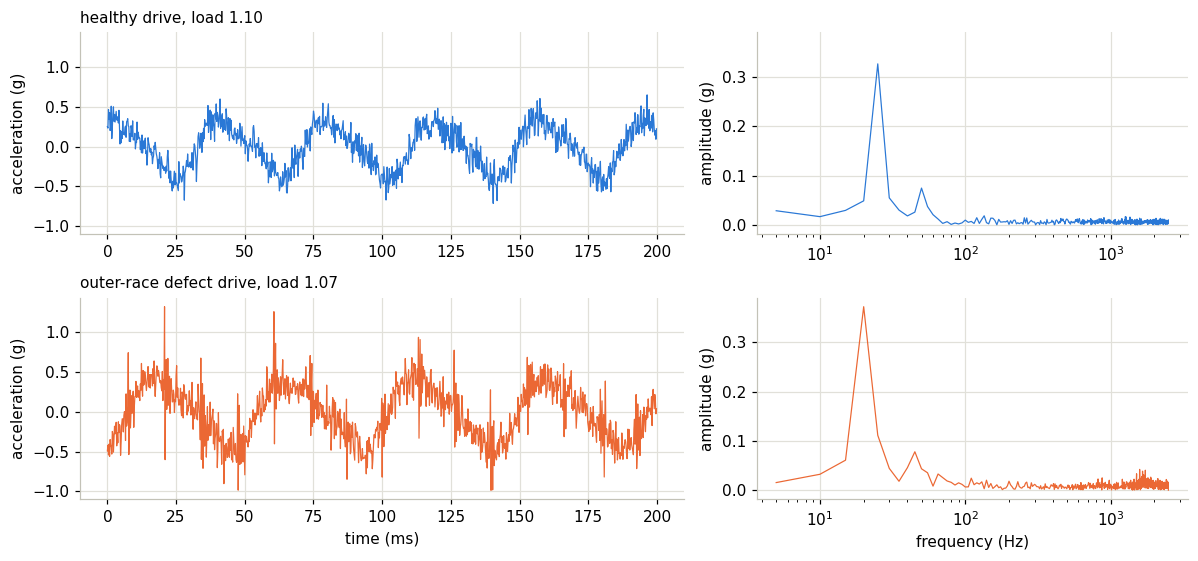

In [9]:
# Figure 1.1: one window from a healthy and a faulty drive at similar load
healthy_id = log[(log.label == 0)].sort_values("load").drive.iloc[-1]
faulty_id = log[(log.label == 1)].sort_values("load").drive.iloc[0]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.2), gridspec_kw=dict(width_ratios=[1.4, 1]), sharey="col")
for row, (d, lab) in enumerate([(healthy_id, 0), (faulty_id, 1)]):
    x = log_raw[d][0]
    t = np.arange(WIN) / FS * 1000
    L = log[log.drive == d].load.iloc[0]
    axes[row, 0].plot(t, x, color=CLASS_COLORS[lab], lw=0.8)
    axes[row, 0].set_ylabel("acceleration (g)")
    axes[row, 0].set_title(f"{CLASS_NAMES[lab]} drive, load {L:.2f}", loc="left", fontsize=10)
    spec = np.abs(np.fft.rfft(x - x.mean())) * 2 / x.size
    fr = np.fft.rfftfreq(x.size, 1 / FS)
    axes[row, 1].semilogx(fr[1:], spec[1:], color=CLASS_COLORS[lab], lw=0.8)
    axes[row, 1].set_ylabel("amplitude (g)")
axes[1, 0].set_xlabel("time (ms)")
axes[1, 1].set_xlabel("frequency (Hz)")
fig.tight_layout()
savefig("ch01_signals")
plt.show()

รูปที่ 1.1 เปรียบเทียบสัญญาณและสเปกตรัมระหว่างชุดขับที่ยังใช้งานได้ดีกับชุดที่บกพร่อง

แม้ว่าเราจะสามารถตรวจจับความผิดปกติได้ด้วยตาเปล่า แต่เหตุผลหนึ่งในการใช้ ML คือไม่ต้องการให้มนุษย์เป็นผู้ตรวจสอบความผิดปกตินี้ โดยเฉพาะเมื่อมีข้อมูลขุดขับจำนวนมาก 

สมมุติว่าเราไม่อยากเสียเวลาสร้างโมเดลตัวจำแนก ลองใช้กฎอย่างง่ายที่เขียนด้วยมือ เราพบว่าการสั่นสะเทือนแบบสุ่มที่มีการแจกแจงแบบเกาส์เซียน (Gaussian distribution) มีค่า *ความโด่ง (kurtosis)* คือค่าโมเมนต์ที่สี่ที่ทำให้เป็นมาตราฐาน (normalized fourth moment) เท่ากับ 3 ดังนั้นเงื่อนไขอย่างง่ายคือ **แจ้งเตือนเมื่อค่าความโด่งมากกว่า 3** แต่จะพบว่าทำงานไม่ได้ดีตามที่คาดหวัง

In [10]:
def report(name, y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    acc = (y_true == y_pred).mean()
    fa = y_pred[y_true == 0].mean()          # false-alarm rate on healthy windows
    miss = 1 - y_pred[y_true == 1].mean()    # miss rate on faulty windows
    print(f"{name:<34s} accuracy {acc:.3f}   false alarms {fa:.3f}   misses {miss:.3f}")
    return acc, fa, miss

report("hand rule: kurtosis > 3", log.label, (log["kurtosis"] > 3).astype(int))

# the same feature, threshold chosen from the data: midpoint between the classes
k_h_max = log["kurtosis"][log.label == 0].max()
k_f_min = log["kurtosis"][log.label == 1].min()
thr = 0.5 * (k_h_max + k_f_min)
print(f"healthy kurtosis max {k_h_max:.3f}, faulty kurtosis min {k_f_min:.3f} -> threshold {thr:.3f}")
report("data-set rule: kurtosis > %.2f" % thr, log.label, (log["kurtosis"] > thr).astype(int))

hand rule: kurtosis > 3            accuracy 0.760   false alarms 0.000   misses 0.480
healthy kurtosis max 2.274, faulty kurtosis min 2.316 -> threshold 2.295
data-set rule: kurtosis > 2.30     accuracy 1.000   false alarms 0.000   misses 0.000


(np.float64(1.0), np.float64(0.0), np.float64(0.0))

จากเอาต์พุตจะเห็นว่าหากตั้งการแจ้งเตือนเมื่อความโด่งมากกว่า 3 ได้ความแม่นยำเพียง 0.76 และมีข้อบกพร่องที่ไม่ถูกแจ้งเตือนถึง 48% ข้อมูลที่ได้จาก ML ชี้ให้เห็นว่าเราต้องลดเงื่อนไขลงเป็นค่าความโด่ง > 2.30 จึงจะได้ความแม่นยำ 100% และไม่มีทั้งข้อบกพร่องที่ไม่ถูกแจ้งเตือน และการแจ้งเตือนที่ผิด

เราสามารถมองภาพการจำแนกได้ชัดเจนขึ้นในระบบ 2 มิติ โดยเลือกลักษณะเด่นเพียง 2 ค่า ดังแสดงในรูปที่ 1.2 

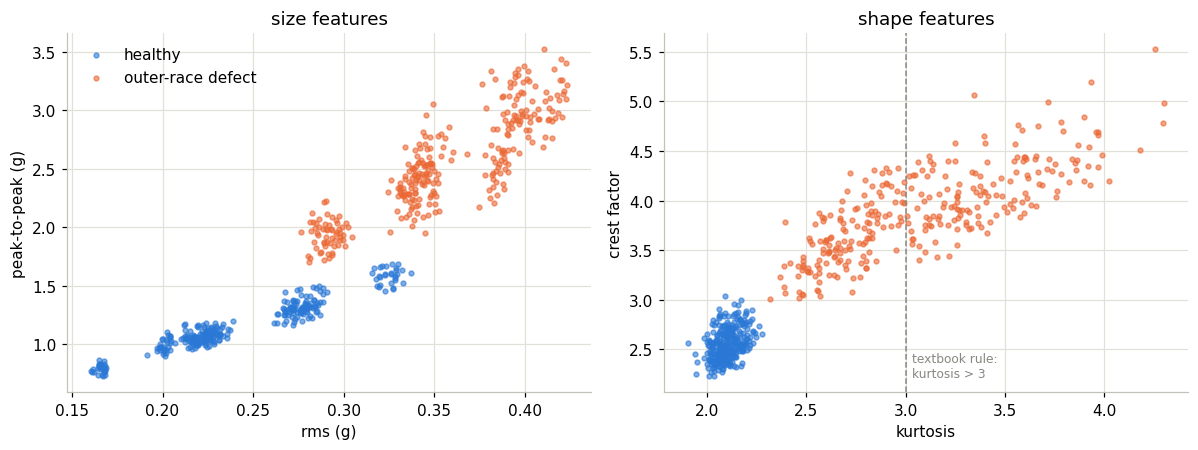

In [11]:
# Figure 1.2: the log in two feature planes
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for lab in (0, 1):
    s = log[log.label == lab]
    axes[0].scatter(s.rms, s["ptp"], s=10, alpha=0.6, color=CLASS_COLORS[lab], label=CLASS_NAMES[lab])
    axes[1].scatter(s["kurtosis"], s.crest, s=10, alpha=0.6, color=CLASS_COLORS[lab], label=CLASS_NAMES[lab])
axes[0].set(xlabel="rms (g)", ylabel="peak-to-peak (g)", title="size features")
axes[1].set(xlabel="kurtosis", ylabel="crest factor", title="shape features")
axes[1].axvline(3.0, color=MUTED, ls="--", lw=1)
axes[1].text(3.03, axes[1].get_ylim()[0] + 0.15, "textbook rule:\nkurtosis > 3", color=MUTED, fontsize=8)
axes[0].legend(loc="upper left")
fig.tight_layout()
savefig("ch01_feature_planes")
plt.show()

รูปที่ 1.2 แสดงการจำแนกชุดขับใน 2 มิติโดยเลือกลักษณะเด่น

จากรูปที่ 1.2 จะเห็นว่าสามารถจำแนกประเภทของชุดขับว่ามีสภาพดีหรือบกพร่องได้โดยลากเส้นแบ่งเขตที่แบ่งกลุ่มข้อมูลสีส้มและน้ำเงินออกจากกัน ในกรณีนี้สามารถใช้เส้นตรงเป็นเส้นแบ่งเขตได้ทั้งภาพซ้ายและขวา กล่าวคือปัญหานี้ถูกจำแนกได้โดยโมเดลเชิงเส้น ตัวอย่างเช่นในรูปด้านขวาคือเมื่อเลือกค่าความโด่ง >2.3 ขณะที่จากเงื่อนไขด้วยมือคือค่าความโด่ง > 3.0 ไม่สามารถจำแนกปัญหานี้ได้อย่างถูกต้อง 100% 

## 1.2 การใช้ ML ควบคู่กับการควบคุม

การควบคุมโดยส่วนใหญ่ที่ได้ศึกษาในวิชาระบบควบคุมจัดอยู่ในประเภท *บนพื้นฐานโมเดล (model-based)* แม้อาจมีผู้แย้งว่าการใช้งานตัวควบคุม PID เพียงปรับค่าพารามิเตอร์โดยไม่จำเป็นต้องรู้โมเดล แต่การปรับค่าให้ได้ผลดีโดยวิธีการที่นิยมใช้เช่น *วิธีซีกเลอร์-นิโคลส์ (Ziegler-Nichols)* จะใช้ประโยชน์จากคุณสมบัติบางตัวของโมเดลที่เรียกว่า *พลานต์ (plant)* ดังนั้นกล่าวโดยรวมได้ว่าการออกแบบตัวควบคุมบนพื้นฐานโมเดลจะเริ่มจากโมเดลทางคณิตศาสตร์ที่สร้างจากความสัมพันธ์ทางฟิสิกส์ที่เกี่ยวข้องเช่น พลวัต จลนศาสตร์ โมเดลของมอเตอร์ โมเดลการรบกวนของเซนเซอร์ เพื่ออนุพัทธ์ตัวควบคุมหรือตัวประมาณค่าสำหรับพลานต์นั้น สิ่งที่แตกต่างสำหรับวิธี ML คือจะเป็นแบบ *ขับเคลื่อนโดยข้อมูล (data-driven)* โดยเริ่มจากเก็บข้อมูลเป็นจำนวนตัวอย่างของอินพุตและเอาต์พุตที่ต้องการ เพื่อหาฟังก์ชันที่เหมาะสมที่เป็นตัวแทนที่ดีของความสัมพันธ์ระหว่างอินพุตและเอาต์พุตของข้อมูลนั้น ตาราง 1.2 สรุปความแตกต่างระหว่างทั้งสอง

| | การควบคุมและประมาณค่าบนพื้นฐานโมเดล | ML |
|---|---|---|
| เริ่มต้นจาก | ฟิสิกส์ : พลวัต จลนศาสตร์ โมเดลระบบไฟฟ้าเชิงกล โมเดลการรบกวน | ข้อมูลตัวอย่าง: บันทึกของอินพุตและเอาต์พุต |
| เครื่องมือหลัก | PID, LQR, MPC, คาลมานฟิลเตอร์ การหาเอกลักษณ์ระบบ | แคลสซิไฟเออร์ (classifier) รีเกรสเซอร์(regressor) คลัสเตอริง (clustering) โครงข่ายประสาทเทียม การเรียนรู้เสริมกำลัง |
| ใช้ได้ดีเมื่อ | โมเดลมีความแม่นยำและทราบย่านการทำงาน | ยากที่จะอนุพัทธ์ความสัมพันธ์แต่ง่ายในการสาธิต |
| การรับประกัน | ค่าเผื่อเสถียรภาพ ความสังเกตได้ ขอบเขตเมื่อโมเดลมีความถูกต้อง | สมรรถนะในเชิงสถิติ |
| ล้มเหลวเมื่อ | มีผลกระทบจากพลวัตที่ไม่ได้โมเดล เช่นแรงเสียดทาน  ระยะคลอน (backlash)  แรงสัมผัส การสึกหรอ | การเลื่อนของการแจกแจง (distribution shift): เงื่อนไขที่ไม่ได้ครอบคลุมโดยข้อมูล |

**ตาราง 1.2** การเปรียบเทียบระหว่างการควบคุมและประมาณค่าบนพื้นฐานโมเดลและวิธี ML

สังเกตว่าขอบเขตระหว่างสองคอลัมน์ไม่ถูกแบ่งแยกอย่างชัดเจน คาลมานฟิลเตอร์ประมาณค่าสถานะจากข้อมูลที่มีการรบกวน การหาเอกลักษณ์ระบบโดยวิธีกำลังสองน้อยสุด (least-square) หาค่าเหมาะที่สุดจากข้อมูลอินพุต-เอาต์พุตที่บันทึกไว้ หรือการควบคุมปรับตัวจะปรับค่าอัตราขยายในระหว่างทำงาน วิธีการเหล่านี้แม้จะถูกจัดอยู่ในประเภทบนพื้นฐานโมเดล แต่อาศัยการเรียนรู้จากข้อมูลในระดับหนึ่ง สิ่งที่แตกต่างใน ML คือโครงสร้างส่วนใหญ่จะมาจากข้อมูล เช่นโครงข่ายประสาทเทียมฟิตพารามิเตอร์จำนวนเป็นล้านตัวโดยไม่ทราบข้อมูลใดๆ เกี่ยวกับพลานต์

ปัญหาหลัก 3 ประเภทในสาขาศาสตร์หุ่นยนต์และระบบอัตโนมัติที่จะกล่าวถึงในเนื้อหาของหนังสือนี้ 

- **การบำรุงรักษาเชิงป้องกัน** ทำนายอาการเริ่มต้นของตลับลูกปืนที่เริ่มสึกหรอ ความเสียหายของฟันเฟือง หรือการทำงานผิดพลาดของมอเตอร์จะฝังอยู่ในสัญญาณที่ตรวจจับได้จากการสั่นสะเทือนและกระแสไฟฟ้า 
- **การตรวจสอบด้วยสายตา** คุณภาพของรอยเชื่อมชิ้นงาน จุดบัดกรีบนแผ่นวงจร หรือผิวโลหะที่ผ่านจากเครื่องซีเอ็นซี อาจสามารถตรวจสอบได้โดยง่ายโดยผู้ชำนาญแต่ยากที่จะเขียนเป็นกฎหรือโปรแกรมให้คอมพิวเตอร์ทำงานแทน 
- **ตัวควบคุมบนพื้นฐานการเรียนรู้** การควบคุมหุ่นยนต์ที่มีแรงจากการสัมผัส ข้อต่อที่มีแรงเสียดทานสูง หรือผลจากอากาศพลศาสตร์ จะไม่สามารถหาโมเดลเชิงวิเคราะห์ได้โดยง่าย 

จุดมุ่งหมายของหนังสือนี้มิใช่การแทนที่ทฤษฎีระบบควบคุมแต่เป็นการเสริมโดย ML เพื่อให้ได้ผลที่ดีที่สุด ฟิสิกส์ยังเป็นสิ่งที่จำเป็นสำหรับการเลือกเซนเซอร์ อัตราการสุ่ม การออกแบบลักษณะเด่น รวมถึงการใช้ตัวควบคุมสำรองในกรณีที่ ML ทำงานผิดพลาด หรือเปรียบเทียบว่า ML ทำงานได้สมเหตุผลหรือไม่ เราจะใช้การเรียนรู้ในจุดที่วิธีทางฟิสิกส์มีช่องว่าง ในตัวอย่างที่ผ่านมาเราได้ใช้ทั้งสองแบบ คือใช้ฟิสิกส์ในการสร้างลักษณะเด่น และใช้ข้อมูลในการแจ้งเตือนความบกพร่องของชุดขับ 

## 1.3 รูปแบบของการเรียนรู้สามประเภท

ปัญหา ML สามารถแบ่งได้เป็น 3 ประเภทหลักดังนี้



<div align="center">
<img src="https://raw.githubusercontent.com/dewdotninja/sharing-github/refs/heads/master/dewninja_logo50.jpg" alt="dewninja"/>
</div>
<div align="center">dew.ninja 2027</div>